**Set Project Root**

In [1]:
import os
from pathlib import Path

%pwd

'd:\\Projects\\Rice_Disease_Prediction_CNN_Model\\research'

In [ ]:

os.chdir("../")

%pwd

'd:\\Projects\\Rice_Disease_Prediction_CNN_Model'

 **Update Configuration YAML**

```yaml
data_visualization:
  root_dir: artifacts/data_visualization
  data_dir: artifacts/data_ingestion/RiceLeafDisease
  sample_images: 16
```


**Update Entity**

In [9]:
from dataclasses import dataclass
from pathlib import Path

@dataclass(frozen=True)
class DataVisualizationConfig:
    root_dir: Path
    data_dir: Path
    sample_images: int

**Update Configuration**

In [10]:
from cnnClassifier.constants import *
from cnnClassifier.utils.common import read_yaml, create_directories

In [11]:
class ConfigurationManager:
    def __init__(
            self,
            config_filepath=CONFIG_FILE_PATH,
            params_filepath=PARAMS_FILE_PATH
    ):
        self.config = read_yaml(config_filepath)
        self.params = read_yaml(params_filepath)

        create_directories([self.config.artifacts_root])

    def get_data_visualization_config(self) -> DataVisualizationConfig:
        config = self.config.data_visualization

        create_directories([config.root_dir])

        data_visualization_config = DataVisualizationConfig(
            root_dir=Path(config.root_dir),
            data_dir=Path(config.data_dir),
            sample_images=int(config.sample_images)
        )

        return data_visualization_config

 **Update Components**

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from cnnClassifier import logger

In [13]:
class DataVisualization:
    def __init__(self, config: DataVisualizationConfig):
        self.config = config
        self.data_dir = Path(config.data_dir)
        self.root_dir = Path(config.root_dir)

        self.image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
        self.class_data = {}
        self.df = None

        sns.set_theme(style="whitegrid")

    # 1. Collect image paths class by class
    def get_dataset_info(self):
        if not self.data_dir.exists():
            raise FileNotFoundError(
                f"Dataset directory not found: {self.data_dir}"
            )

        self.class_data = {}

        for class_dir in sorted(self.data_dir.iterdir()):
            if class_dir.is_dir():
                image_paths = [
                    path for path in class_dir.rglob("*")
                    if path.is_file()
                    and path.suffix.lower() in self.image_extensions
                ]
                self.class_data[class_dir.name] = image_paths

        if not self.class_data:
            raise ValueError(
                "No class folders found. Check data_dir; it must contain "
                "one subfolder per disease class."
            )

        self.df = pd.DataFrame({
            "Class": list(self.class_data.keys()),
            "Image_Count": [
                len(paths) for paths in self.class_data.values()
            ]
        })

        logger.info("Dataset information collected successfully")
        return self.df

    # 2. Print and save dataset summary
    def dataset_summary(self):
        total_images = int(self.df["Image_Count"].sum())

        print("=" * 55)
        print("RICE LEAF DATASET SUMMARY")
        print("=" * 55)
        print(f"Dataset path : {self.data_dir}")
        print(f"Total classes: {len(self.df)}")
        print(f"Total images : {total_images}")
        print("\nClass-wise image count:")
        display(self.df)

        self.df.to_csv(
            self.root_dir / "dataset_summary.csv",
            index=False
        )

    # 3. Plot class distribution
    def plot_class_distribution(self):
        plt.figure(figsize=(12, 6))

        ax = sns.barplot(
            data=self.df,
            x="Class",
            y="Image_Count",
            hue="Class",
            palette="viridis",
            legend=False
        )

        ax.set_title("Rice Leaf Disease — Class Distribution",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Disease class")
        ax.set_ylabel("Number of images")
        plt.xticks(rotation=40, ha="right")
        plt.tight_layout()

        plt.savefig(
            self.root_dir / "class_distribution.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

    # 4. Plot class percentage
    def plot_class_percentage(self):
        counts = self.df["Image_Count"]
        if counts.sum() == 0:
            raise ValueError("The dataset contains no images.")

        plt.figure(figsize=(9, 9))
        plt.pie(
            counts,
            labels=self.df["Class"],
            autopct="%1.1f%%",
            startangle=90
        )
        plt.title("Class-wise Percentage Distribution")
        plt.tight_layout()

        plt.savefig(
            self.root_dir / "class_percentage.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

    # 5. Display sample images from each class
    def plot_sample_images(self):
        samples = []

        for class_name, image_paths in self.class_data.items():
            if image_paths:
                samples.append((class_name, image_paths[0]))

        samples = samples[:self.config.sample_images]

        if not samples:
            raise ValueError("No readable sample images found.")

        n_cols = 4
        n_rows = int(np.ceil(len(samples) / n_cols))

        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(16, 4 * n_rows),
            squeeze=False
        )
        axes = axes.flatten()

        for ax, (class_name, image_path) in zip(axes, samples):
            try:
                with Image.open(image_path) as image:
                    ax.imshow(image.convert("RGB"))
                ax.set_title(class_name)
                ax.axis("off")
            except Exception as error:
                ax.set_title(f"{class_name}\nUnable to open")
                ax.axis("off")
                logger.warning(f"Could not open {image_path}: {error}")

        for ax in axes[len(samples):]:
            ax.axis("off")

        fig.suptitle("Sample Images from Each Rice Disease Class",
                     fontsize=16)
        plt.tight_layout()

        plt.savefig(
            self.root_dir / "sample_images.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

    # 6. Analyze image dimensions and formats
    def image_dimension_analysis(self):
        image_info = []

        for class_name, image_paths in self.class_data.items():
            for image_path in image_paths:
                try:
                    with Image.open(image_path) as image:
                        width, height = image.size
                        image_info.append({
                            "Class": class_name,
                            "Width": width,
                            "Height": height,
                            "Format": image.format
                        })
                except Exception as error:
                    logger.warning(
                        f"Skipping unreadable image {image_path}: {error}"
                    )

        dimension_df = pd.DataFrame(image_info)

        if dimension_df.empty:
            raise ValueError("No valid images available for dimension analysis.")

        dimension_df.to_csv(
            self.root_dir / "image_dimensions.csv",
            index=False
        )

        print("Image dimension summary:")
        display(dimension_df[["Width", "Height"]].describe())

        plt.figure(figsize=(10, 6))
        sns.scatterplot(
            data=dimension_df,
            x="Width",
            y="Height",
            hue="Class",
            alpha=0.6
        )
        plt.title("Image Width vs Height")
        plt.tight_layout()

        plt.savefig(
            self.root_dir / "image_dimensions.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

    # 7. Run all visualization tasks
    def run_visualization(self):
        self.get_dataset_info()
        self.dataset_summary()
        self.plot_class_distribution()
        self.plot_class_percentage()
        self.plot_sample_images()
        self.image_dimension_analysis()

        logger.info("Data visualization completed successfully")

 **Update Pipeline**

[2026-11-09 20:28:05,167: INFO: common: yaml file: config\config.yaml loaded successfully]
[2026-11-09 20:28:05,171: INFO: common: yaml file: params.yaml loaded successfully]
[2026-11-09 20:28:05,175: INFO: common: created directory at: artifacts]
[2026-11-09 20:28:05,177: INFO: common: created directory at: artifacts/data_visualization]
[2026-11-09 20:28:05,970: INFO: 2694558366: Dataset information collected successfully]
RICE LEAF DATASET SUMMARY
Dataset path : artifacts\data_ingestion\RiceLeafDiseaseBD
Total classes: 6
Total images : 9769

Class-wise image count:


,Class,Image_Count
0,Blast,1326
1,Brown spot,2178
2,Healthy,1575
3,Leaf smut,724
4,Rice Tungro,2244
5,Sheath blight,1722


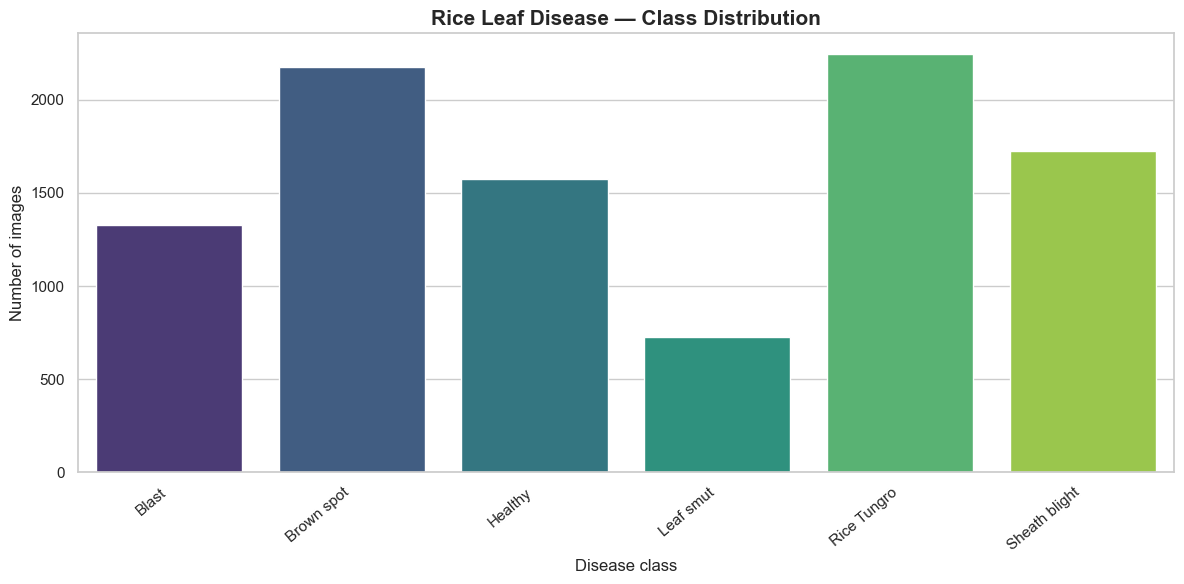

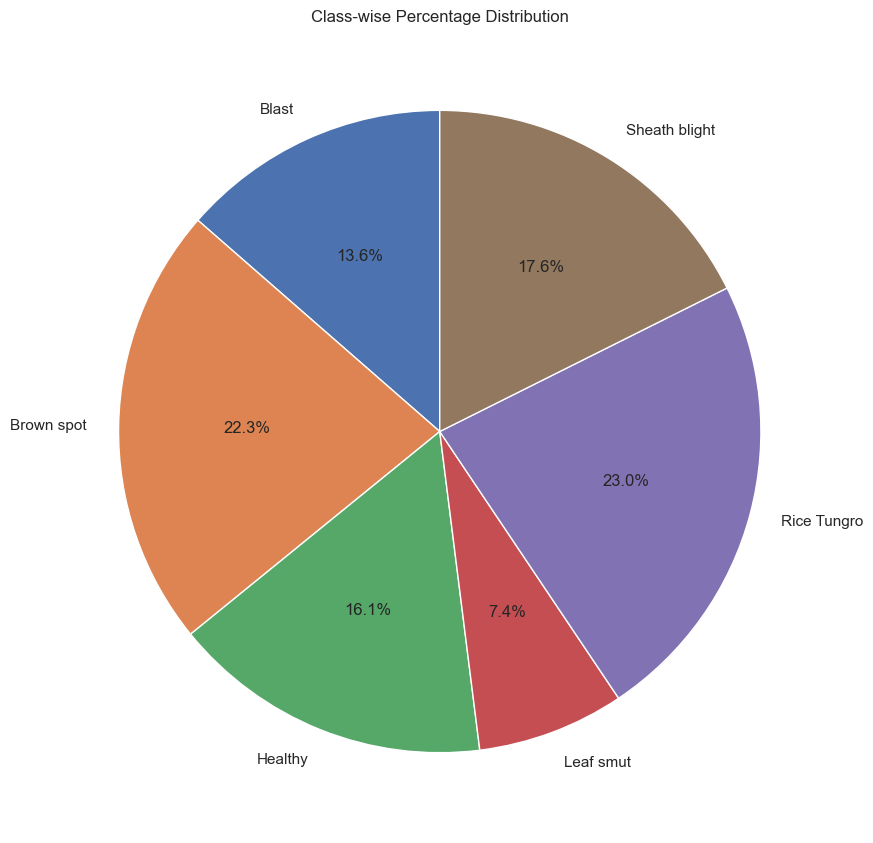

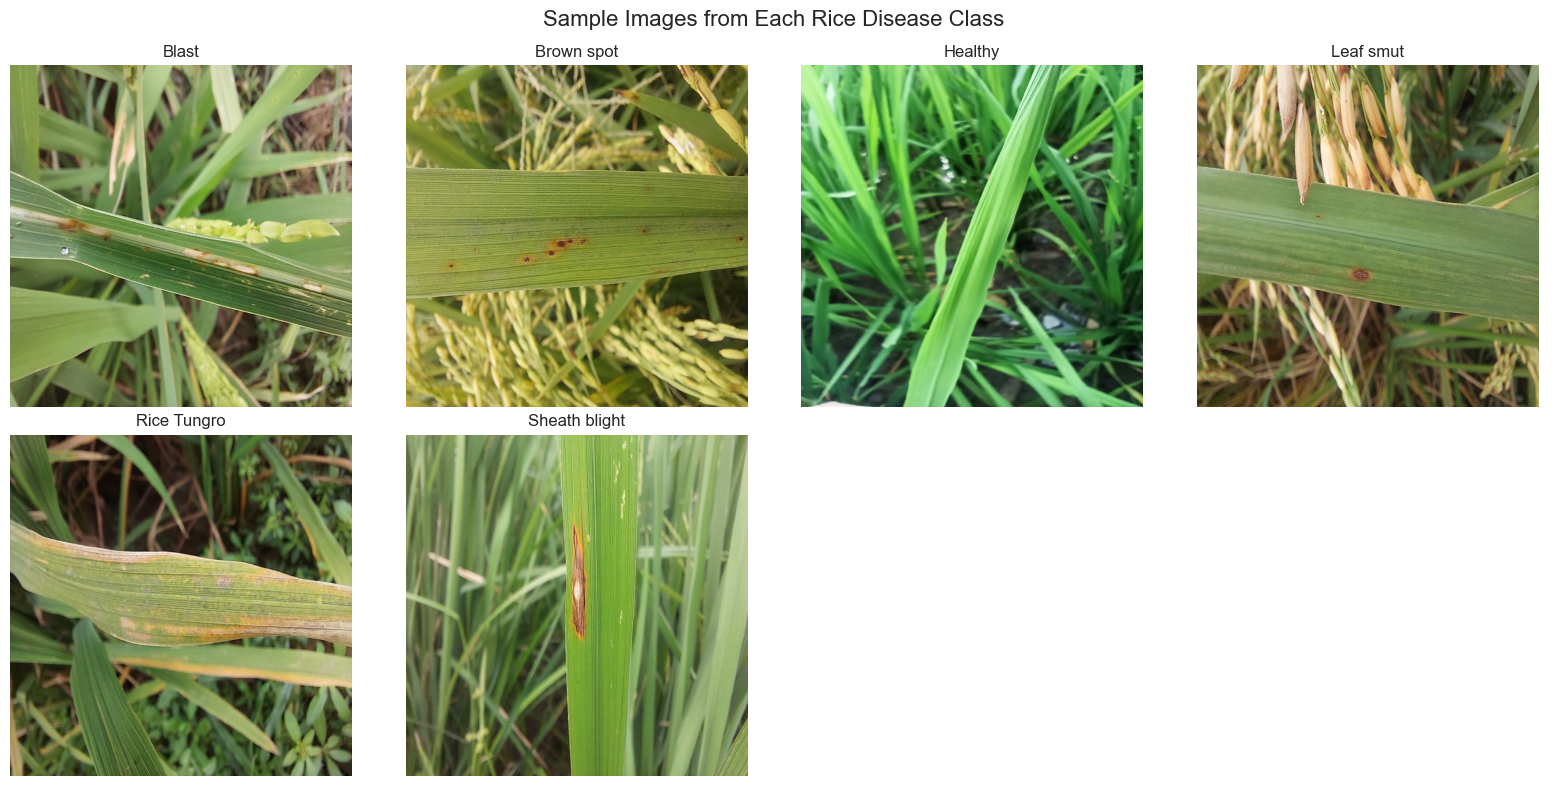

Image dimension summary:


,Width,Height
count,9769.0,9769.0
mean,1024.0,1024.0
std,0.0,0.0
min,1024.0,1024.0
25%,1024.0,1024.0
50%,1024.0,1024.0
75%,1024.0,1024.0
max,1024.0,1024.0


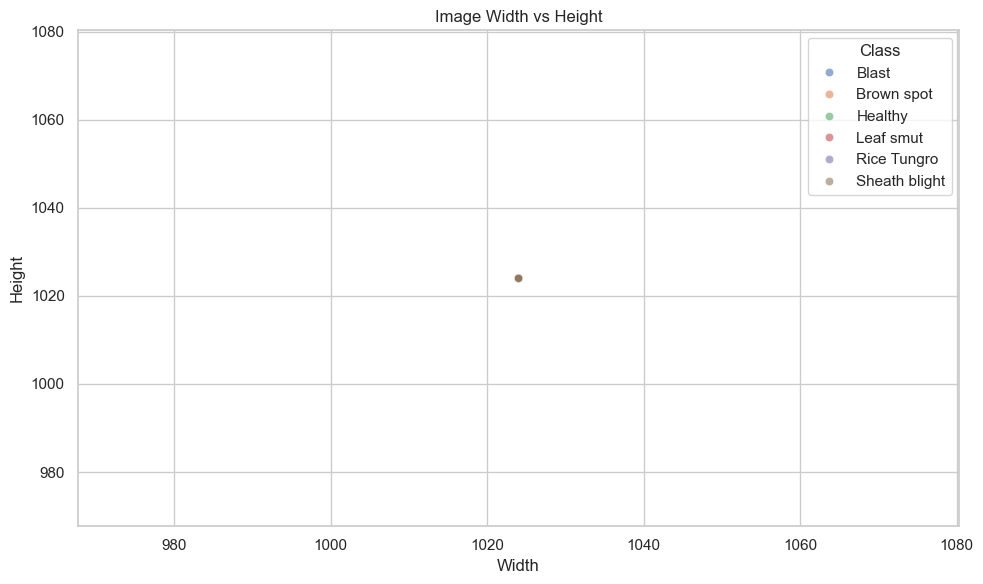

[2026-11-09 20:28:24,413: INFO: 2694558366: Data visualization completed successfully]


In [14]:
try:
    config = ConfigurationManager()

    data_visualization_config = (
        config.get_data_visualization_config()
    )

    data_visualization = DataVisualization(
        config=data_visualization_config
    )

    data_visualization.run_visualization()

except Exception as e:
    logger.exception(e)
    raise